<a href="https://colab.research.google.com/github/ethereal-arko/Cat-Dog_Image_Classification_using_TransferLearning.ipynb/blob/main/Cat%26Dog_Image_Classification_using_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Cat vs Dog Image Classification using Transfer Learning

## 1. Project Overview

This project focuses on classifying images into two categories: **Cat** and **Dog** using Deep Learning and Transfer Learning.

Instead of training a Convolutional Neural Network (CNN) from scratch, we will use a pretrained **MobileNetV2** model as a feature extractor. MobileNetV2 has already learned useful visual features from a large image dataset, which can help us perform image classification with less training.

We will use a balanced subset of the Cat vs Dog dataset containing 1,000 cat images and 1,000 dog images.

## 2. Project Objectives

- Understand and implement Transfer Learning.
- Explore and preprocess an image classification dataset.
- Use MobileNetV2 for extracting image features.
- Build and train a classification model.
- Evaluate model performance using appropriate metrics.
- Analyze incorrect predictions and explore possible improvements.

## 3. Technologies and Libraries

- Python
- TensorFlow and Keras
- TensorFlow Hub
- NumPy
- Matplotlib
- Pillow (PIL)
- Scikit-learn
- Google Colab
- Kaggle API

## 4. Dataset

**Dataset:** Cat vs Dog Dataset  
**Source:** Kaggle  
**Classes:**
- Cat (0)
- Dog (1)

We will initially use 2,000 images, with 1,000 images from each class.

## 5. Model Architecture

We will use **MobileNetV2** as a pretrained feature extractor and add a Dense output layer for binary classification.

## 6. Evaluation

Model performance will be evaluated using:

- Accuracy
- Loss
- Precision
- Recall
- F1-score
- Confusion Matrix



## 2. Importing Dependencies

In this section, we will import the libraries required for dataset handling, image processing, visualization, data splitting, and deep learning.

We will use TensorFlow and TensorFlow Hub to implement the pretrained MobileNetV2 model.


In [1]:

import os
import random
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

import tensorflow as tf
import tensorflow_hub as hub

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


All libraries imported successfully!
TensorFlow version: 2.21.0



## 3. Kaggle Authentication and Dataset Download

### 3.1 Installing Kaggle API

We will use the Kaggle API to download the dataset directly into the Google Colab environment.


In [2]:

!pip install -q kaggle

print("Kaggle API installed successfully!")


Kaggle API installed successfully!



### 3.2 Configuring Kaggle Authentication

We will retrieve our Kaggle username and API token from Google Colab Secrets and configure them as environment variables.

This allows us to authenticate with Kaggle without exposing our credentials directly in the notebook.


In [3]:

from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("kaggle_username")
os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_api_token")

print("Kaggle authentication configured successfully!")


Kaggle authentication configured successfully!



### 3.3 Downloading the Dataset

We will download the Cat vs Dog dataset from Kaggle using its dataset identifier.


In [4]:

!kaggle datasets download -d anubhab098/cat-vs-dog-dataset


Dataset URL: https://www.kaggle.com/datasets/anubhab098/cat-vs-dog-dataset
License(s): apache-2.0
100% 545M/545M [00:10<00:00, 54.7MB/s]




## 4. Dataset Extraction and Initial Inspection

### 4.1 Extracting the Dataset

The downloaded dataset is stored as a ZIP file. We will extract its contents into the Google Colab working directory so that the images can be accessed for further processing.


In [5]:

zip_path = "/content/cat-vs-dog-dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/")

print("The dataset has been extracted successfully!")


The dataset has been extracted successfully!



### 4.2 Inspecting the Directory Structure

After extraction, we will inspect the available files and directories to understand how the dataset is organized.


In [6]:

print("Files and directories in /content/:")

for item in os.listdir("/content/"):
    print(item)


Files and directories in /content/:
.config
train
cat-vs-dog-dataset.zip
sample_data



### 4.3 Inspecting Image Files

The dataset contains separate directories for Cat and Dog images. We will retrieve the image filenames from both directories and examine the number of available images in each class.


In [7]:

cat_dir = "/content/train/Cat/"
dog_dir = "/content/train/Dog/"

cat_filenames = os.listdir(cat_dir)
dog_filenames = os.listdir(dog_dir)

print("Number of cat images:", len(cat_filenames))
print("Number of dog images:", len(dog_filenames))

print("\nFirst 10 cat filenames:")
print(cat_filenames[:10])

print("\nFirst 10 dog filenames:")
print(dog_filenames[:10])


Number of cat images: 12503
Number of dog images: 12497

First 10 cat filenames:
['cat.4740.jpg', 'cat.10252.jpg', 'cat.9738.jpg', 'cat.4829.jpg', 'cat.2847.jpg', 'cat.6867.jpg', 'cat.376.jpg', 'cat.7812.jpg', 'cat.1137.jpg', 'cat.10099.jpg']

First 10 dog filenames:
['dog.7170.jpg', 'dog.11566.jpg', 'dog.3091.jpg', 'dog.360.jpg', 'dog.871.jpg', 'dog.11635.jpg', 'dog.7914.jpg', 'dog.2490.jpg', 'dog.3546.jpg', 'dog.3026.jpg']



## 5. Exploratory Data Analysis (EDA)

### 5.1 Visualizing Sample Images

In this section, we will explore the dataset through visualizations to understand the appearance and characteristics of cat and dog images.

We will display a few sample images from both classes.


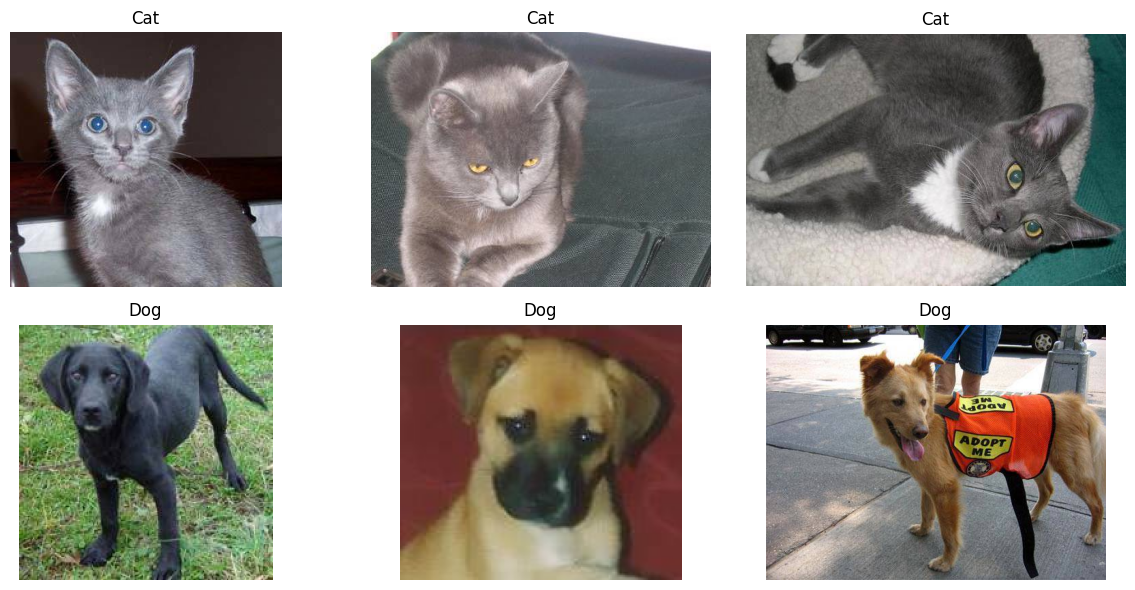

In [8]:

plt.figure(figsize=(12, 6))

# Display sample cat images
for i in range(3):
    img = mpimg.imread(os.path.join(cat_dir, cat_filenames[i]))

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title("Cat")
    plt.axis("off")

# Display sample dog images
for i in range(3):
    img = mpimg.imread(os.path.join(dog_dir, dog_filenames[i]))

    plt.subplot(2, 3, i + 4)
    plt.imshow(img)
    plt.title("Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

sample_cat = Image.open(os.path.join(cat_dir, cat_filenames[0]))
sample_dog = Image.open(os.path.join(dog_dir, dog_filenames[0]))

print("Cat image size:", sample_cat.size)
print("Cat image mode:", sample_cat.mode)

print("\nDog image size:", sample_dog.size)
print("Dog image mode:", sample_dog.mode)


Cat image size: (321, 302)
Cat image mode: RGB

Dog image size: (199, 200)
Dog image mode: RGB



### 5.3 Analyzing Image Dimensions

The images in the dataset have different original dimensions. Since deep learning models require consistent input dimensions, we will examine the image sizes before applying resizing during preprocessing.


In [10]:

sample_sizes = []

for filename in cat_filenames[:100]:
    with Image.open(os.path.join(cat_dir, filename)) as img:
        sample_sizes.append(img.size)

for filename in dog_filenames[:100]:
    with Image.open(os.path.join(dog_dir, filename)) as img:
        sample_sizes.append(img.size)

widths = [size[0] for size in sample_sizes]
heights = [size[1] for size in sample_sizes]

print("Sampled images:", len(sample_sizes))
print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))


Sampled images: 200
Minimum width: 136
Maximum width: 500
Minimum height: 104
Maximum height: 500



### 5.4 Class Distribution

We will visualize the number of available images in each class to understand the class distribution of the dataset.

A balanced dataset helps prevent the model from becoming biased toward one particular class.


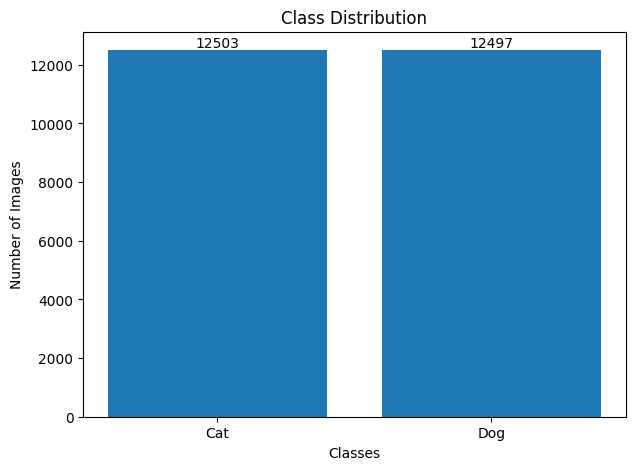

In [11]:

class_counts = {
    "Cat": len(cat_filenames),
    "Dog": len(dog_filenames)
}

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

for i, count in enumerate(class_counts.values()):
    plt.text(i, count + 100, str(count), ha="center")

plt.show()



## 6. Image Preprocessing

### 6.1 Selecting a Balanced Subset

The original dataset contains approximately 25,000 images. To reduce computational requirements and make experimentation easier, we will select a balanced subset of 2,000 images.

The subset will contain:
- 1,000 Cat images
- 1,000 Dog images

Random sampling will be used to select the images from both classes.


In [12]:

# Select 1,000 random images from each class

cat_images = random.sample(cat_filenames, 1000)
dog_images = random.sample(dog_filenames, 1000)

print("Selected cat images:", len(cat_images))
print("Selected dog images:", len(dog_images))
print("Total selected images:", len(cat_images) + len(dog_images))



Selected cat images: 1000
Selected dog images: 1000
Total selected images: 2000



### 6.2 Loading, Resizing and Converting Images

The selected images have different original dimensions. We will resize every image to 224 × 224 pixels and convert it into RGB format.

Finally, the processed images will be stored as NumPy arrays for model training.


In [13]:

data = []

# Process cat images
for img_file in cat_images:
    image_path = os.path.join(cat_dir, img_file)

    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize((224, 224))
        image = np.array(image)

    data.append(image)

# Process dog images
for img_file in dog_images:
    image_path = os.path.join(dog_dir, img_file)

    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize((224, 224))
        image = np.array(image)

    data.append(image)

print("Total processed images:", len(data))
print("Image shape:", data[0].shape)
print("Image data type:", data[0].dtype)


Total processed images: 2000
Image shape: (224, 224, 3)
Image data type: uint8



### 6.3 Creating Class Labels

Machine learning models require numerical labels to identify different classes.

We will assign:
- Cat images → 0
- Dog images → 1

The labels will follow the same order as the processed image data.


In [14]:

cat_labels = [0] * 1000
dog_labels = [1] * 1000

labels = cat_labels + dog_labels

print("Total labels:", len(labels))
print("Cat labels:", labels.count(0))
print("Dog labels:", labels.count(1))


Total labels: 2000
Cat labels: 1000
Dog labels: 1000



### 6.4 Converting Images and Labels into NumPy Arrays

We will convert the processed images and their corresponding labels into NumPy arrays.

This will make the data suitable for efficient numerical operations and model training.


In [15]:

X = np.array(data)
y = np.array(labels)

print("Image data shape:", X.shape)
print("Label data shape:", y.shape)

print("Image data type:", X.dtype)
print("Label data type:", y.dtype)


Image data shape: (2000, 224, 224, 3)
Label data shape: (2000,)
Image data type: uint8
Label data type: int64



## 7. Splitting the Dataset

We will divide the dataset into three subsets: training, validation, and testing.

- Training set: 70%
- Validation set: 15%
- Testing set: 15%

We will use stratified sampling to maintain the same class distribution across all three subsets.

A fixed random state will ensure reproducibility.


In [16]:

# First, separate the test set (15%)

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining data into training (70%) and validation (15%)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.17647,
    random_state=42,
    stratify=y_temp
)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


Training images: (1400, 224, 224, 3)
Validation images: (300, 224, 224, 3)
Testing images: (300, 224, 224, 3)

Training labels: (1400,)
Validation labels: (300,)
Testing labels: (300,)


In [17]:

print("Training set:")
print("Cat:", np.sum(y_train == 0))
print("Dog:", np.sum(y_train == 1))

print("\nValidation set:")
print("Cat:", np.sum(y_val == 0))
print("Dog:", np.sum(y_val == 1))

print("\nTesting set:")
print("Cat:", np.sum(y_test == 0))
print("Dog:", np.sum(y_test == 1))


Training set:
Cat: 700
Dog: 700

Validation set:
Cat: 150
Dog: 150

Testing set:
Cat: 150
Dog: 150



### 7.3 Image Normalization

The original image pixel values range from 0 to 255.

To make the input values suitable for the pretrained MobileNetV2 feature extractor, we will normalize all images by dividing their pixel values by 255.

This scales the pixel values to the range [0, 1].

We will also convert the image arrays to float32 for efficient numerical computation.


In [18]:

X_train_scaled = X_train.astype("float32") / 255.0
X_val_scaled = X_val.astype("float32") / 255.0
X_test_scaled = X_test.astype("float32") / 255.0

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nData type:", X_train_scaled.dtype)
print("Minimum pixel value:", X_train_scaled.min())
print("Maximum pixel value:", X_train_scaled.max())


Training data shape: (1400, 224, 224, 3)
Validation data shape: (300, 224, 224, 3)
Testing data shape: (300, 224, 224, 3)

Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0



## 8. Understanding MobileNetV2 and Transfer Learning

### 8.1 Introduction to Transfer Learning

Transfer Learning is a Deep Learning technique in which a model trained on one task is reused as the starting point for a different but related task.

Instead of training a neural network from scratch, we utilize the knowledge and features learned by a pretrained model.

In this project, we will use MobileNetV2, which was pretrained on the ImageNet dataset.

We will use the pretrained network as a feature extractor and add a new Dense layer to classify images into two categories: Cat and Dog.



### 8.2 Introduction to MobileNetV2

MobileNetV2 is a lightweight Convolutional Neural Network (CNN) architecture designed for efficient image recognition, particularly on devices with limited computational resources.

It uses two important techniques:

**1. Depthwise Separable Convolution**

Instead of performing standard convolution directly across all input channels, it separates the operation into depthwise convolution and pointwise convolution. This reduces computational cost.

**2. Inverted Residuals and Linear Bottlenecks**

MobileNetV2 uses inverted residual blocks with linear bottleneck layers to improve efficiency while maintaining useful feature representations.

These architectural improvements make MobileNetV2 suitable for transfer learning and image classification tasks.



### 8.3 MobileNetV2 as a Feature Extractor

A pretrained MobileNetV2 model has already learned useful visual features from the ImageNet dataset.

We will remove its original classification head and use the network to extract image features.

The pretrained weights will remain frozen during training. This means that the original MobileNetV2 parameters will not be updated.

We will add a new Dense layer with two output units to classify the extracted features into Cat and Dog categories.



## 9. Building the Transfer Learning Model

### 9.1 Installing and Importing Required Libraries

We will install TensorFlow Hub and tf-keras to load and use the pretrained MobileNetV2 feature extractor.

The legacy Keras compatibility setting will be configured before importing TensorFlow-related libraries.


In [19]:

!pip install -q tensorflow-hub tf-keras

import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow_hub as hub
import tf_keras

print("TensorFlow Hub version:", hub.__version__)
print("tf-keras version:", tf_keras.__version__)


TensorFlow Hub version: 0.16.1
tf-keras version: 2.21.0



### 9.2 Loading the Pretrained MobileNetV2 Model

We will load the pretrained MobileNetV2 feature extractor from TensorFlow Hub.

The model accepts images of shape (224, 224, 3) and generates a 1280-dimensional feature vector for each image.

We will set trainable=False to freeze the pretrained weights and prevent them from being updated during training.


In [20]:

mobilenet_model = "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4"

pretrained_model = hub.KerasLayer(
    mobilenet_model,
    input_shape=(224, 224, 3),
    trainable=False
)

print("Pretrained MobileNetV2 loaded successfully!")


Pretrained MobileNetV2 loaded successfully!



### 9.3 Building the Classification Model

We will construct a Sequential model consisting of two main components:

1. Pretrained MobileNetV2 feature extractor.
2. A Dense output layer with two units for Cat and Dog classification.

The output layer will generate logits, which represent the unnormalized prediction scores for the two classes.


In [21]:

num_classes = 2

model = tf_keras.Sequential([
    pretrained_model,
    tf_keras.layers.Dense(num_classes)
])

model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense (Dense)               (None, 2)                 2562      
                                                                 
Total params: 2260546 (8.62 MB)
Trainable params: 2562 (10.01 KB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________



## 10. Compiling the Model

### 10.1 Model Compilation

Before training, we need to compile the model by specifying an optimizer, loss function, and evaluation metric.

- **Optimizer:** Adam, which updates the trainable parameters to minimize the loss.
- **Loss Function:** Sparse Categorical Crossentropy, suitable for multiclass classification with integer-encoded labels.
- **Metric:** Accuracy, used to monitor the proportion of correctly classified images.

Since the model outputs logits, we will set `from_logits=True` in the loss function.


In [22]:

model.compile(
    optimizer=tf_keras.optimizers.Adam(),
    loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!



## 11. Training the Model

### 11.1 Model Training

We will train the model using the training dataset and monitor its performance on the validation dataset.

The pretrained MobileNetV2 weights will remain frozen, while the Dense classification layer will learn to distinguish between cat and dog images.

We will initially train the model for 5 epochs to establish a baseline performance.


In [23]:

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=5,
    batch_size=32,
    verbose=1
)


Epoch 1/5
44/44 [==============================] - 76s 2s/step - loss: 0.2072 - accuracy: 0.9150 - val_loss: 0.0799 - val_accuracy: 0.9700
Epoch 2/5
44/44 [==============================] - 60s 1s/step - loss: 0.0604 - accuracy: 0.9807 - val_loss: 0.0633 - val_accuracy: 0.9767
Epoch 3/5
44/44 [==============================] - 61s 1s/step - loss: 0.0480 - accuracy: 0.9864 - val_loss: 0.0673 - val_accuracy: 0.9767
Epoch 4/5
44/44 [==============================] - 69s 2s/step - loss: 0.0341 - accuracy: 0.9900 - val_loss: 0.0574 - val_accuracy: 0.9700
Epoch 5/5
44/44 [==============================] - 68s 2s/step - loss: 0.0256 - accuracy: 0.9950 - val_loss: 0.0490 - val_accuracy: 0.9800



## 12. Visualizing Training Performance

### 12.1 Training and Validation Accuracy

We will visualize the training and validation accuracy across all epochs.

This plot helps us understand how effectively the model learns from the training data and how well it generalizes to unseen validation images.


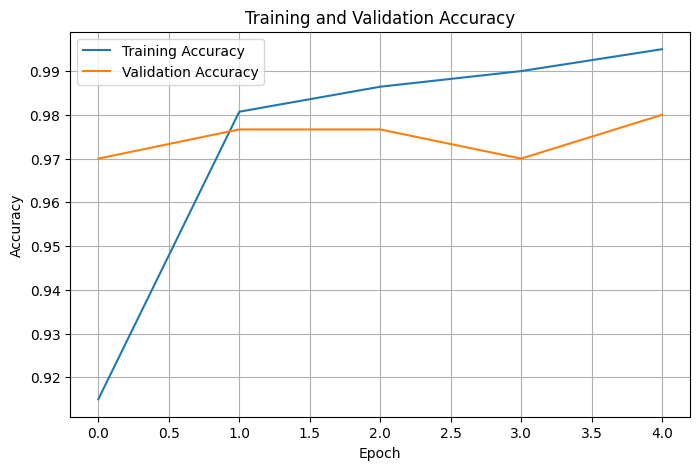

In [24]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()



### 12.2 Training and Validation Loss

We will also visualize the training and validation loss across epochs.

A decreasing loss indicates that the model is improving its predictions. Comparing both curves helps identify possible overfitting or underfitting.


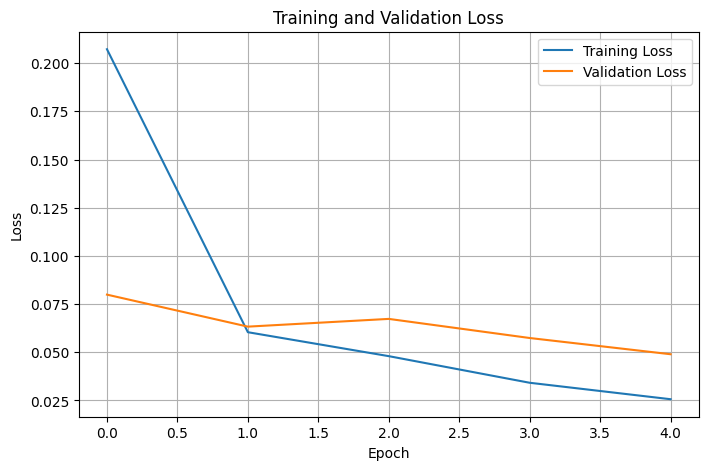

In [25]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


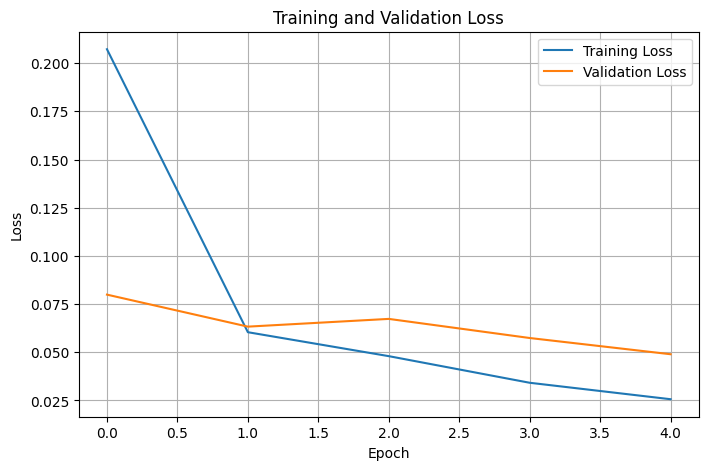

In [26]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()



## 13. Model Evaluation on Test Dataset

### 13.1 Evaluating Test Accuracy and Loss

After training and validation, we will evaluate the model using the independent test dataset.

The test dataset was not used during model training or validation. Therefore, its results provide an estimate of how well the model generalizes to unseen images.

We will evaluate the model using test loss and test accuracy.


In [27]:

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


10/10 [==============================] - 11s 1s/step - loss: 0.0356 - accuracy: 0.9867

Test Loss: 0.03558208420872688
Test Accuracy: 0.9866666793823242



### 13.2 Generating Predictions

The model produces two logits for each input image, representing the scores for the Cat and Dog classes.

We will apply softmax to convert these logits into probabilities and use argmax to determine the predicted class.


In [28]:

y_logits = model.predict(X_test_scaled)

y_probabilities = tf.nn.softmax(y_logits).numpy()

y_pred = np.argmax(y_probabilities, axis=1)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])


10/10 [==============================] - 13s 1s/step
Actual labels: [0 0 0 1 1 1 1 1 0 1]
Predicted labels: [0 0 0 1 1 1 1 1 0 1]



## 14. Classification Performance Analysis

### 14.1 Confusion Matrix

A confusion matrix provides a detailed comparison between the actual and predicted class labels.

It shows the number of correctly and incorrectly classified images for each class.

For this project:
- Class 0 represents Cat.
- Class 1 represents Dog.


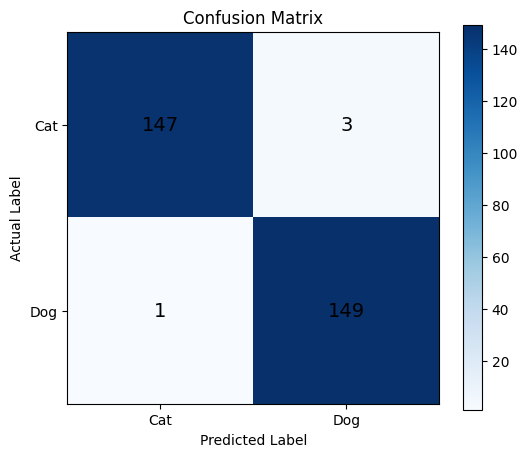

Confusion Matrix:
[[147   3]
 [  1 149]]


In [29]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Cat", "Dog"])
plt.yticks([0, 1], ["Cat", "Dog"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)

plt.colorbar()
plt.show()

print("Confusion Matrix:")
print(cm)



### 14.2 Classification Report

We will generate a classification report containing precision, recall, and F1-score for each class.

- **Precision:** Measures how many images predicted as a particular class actually belong to that class.
- **Recall:** Measures how many actual images of a class were correctly identified.
- **F1-score:** Represents the harmonic mean of precision and recall.

These metrics provide a more comprehensive evaluation of the classification model.


In [30]:

print(classification_report(
    y_test,
    y_pred,
    target_names=["Cat", "Dog"],
    digits=4
))


              precision    recall  f1-score   support

         Cat     0.9932    0.9800    0.9866       150
         Dog     0.9803    0.9933    0.9868       150

    accuracy                         0.9867       300
   macro avg     0.9868    0.9867    0.9867       300
weighted avg     0.9868    0.9867    0.9867       300




## 15. Error Analysis

### 15.1 Identifying Misclassified Images

Error analysis helps us understand the limitations of the trained model.

We will identify images where the predicted class does not match the actual class and visualize them along with their predicted probabilities.

This allows us to examine the types of images that the model finds difficult to classify.


In [31]:

misclassified_indices = np.where(y_test != y_pred)[0]

print("Total misclassified images:", len(misclassified_indices))

for index in misclassified_indices:
    actual_class = "Cat" if y_test[index] == 0 else "Dog"
    predicted_class = "Cat" if y_pred[index] == 0 else "Dog"
    confidence = np.max(y_probabilities[index]) * 100

    print(f"Index: {index}")
    print(f"Actual: {actual_class}")
    print(f"Predicted: {predicted_class}")
    print(f"Prediction Confidence: {confidence:.2f}%")
    print("-" * 35)


Total misclassified images: 4
Index: 149
Actual: Dog
Predicted: Cat
Prediction Confidence: 77.90%
-----------------------------------
Index: 180
Actual: Cat
Predicted: Dog
Prediction Confidence: 92.39%
-----------------------------------
Index: 190
Actual: Cat
Predicted: Dog
Prediction Confidence: 81.18%
-----------------------------------
Index: 215
Actual: Cat
Predicted: Dog
Prediction Confidence: 51.99%
-----------------------------------



### 15.2 Visualizing Misclassified Images

We will visualize the misclassified images to investigate possible reasons behind incorrect predictions.

Each image will display its actual class, predicted class, and prediction confidence.


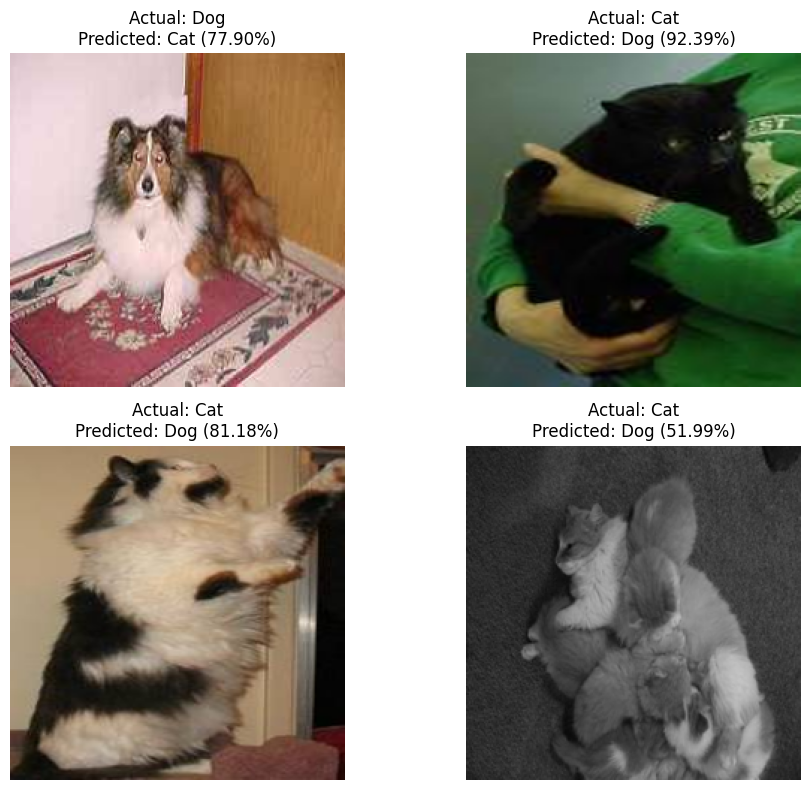

In [32]:

num_errors = len(misclassified_indices)

if num_errors > 0:
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.flatten()

    for i, index in enumerate(misclassified_indices):
        actual_class = "Cat" if y_test[index] == 0 else "Dog"
        predicted_class = "Cat" if y_pred[index] == 0 else "Dog"
        confidence = np.max(y_probabilities[index]) * 100

        axes[i].imshow(X_test[index])
        axes[i].set_title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class} ({confidence:.2f}%)"
        )
        axes[i].axis("off")

    for i in range(num_errors, 4):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images found.")



### Error Analysis Observation

The model misclassified only 4 out of 300 test images.

Upon visual inspection, some of the misclassified images appeared to contain unusual visual characteristics, such as different poses, backgrounds, lighting conditions, or unclear features.

These factors may have contributed to the incorrect predictions. This suggests that even a model with high overall accuracy can struggle with certain challenging images.



## 16. Saving the Trained Model

Saving the trained model allows us to reuse it for future predictions without repeating the training process.

We will save the complete model, including its architecture, trained parameters, and compilation configuration.


In [33]:

model.save("cat_dog_mobilenetv2.keras")

print("Model saved successfully!")


Model saved successfully!



## 17. Loading the Saved Model and Making Predictions

### 17.1 Loading the Saved Model

We will reload the previously saved model to verify that it can be restored and reused without retraining.

This step also demonstrates how a trained model can be used for future image classification tasks.


In [34]:

loaded_model = tf_keras.models.load_model(
    "cat_dog_mobilenetv2.keras",
    custom_objects={"KerasLayer": hub.KerasLayer}
)

print("Saved model loaded successfully!")


Saved model loaded successfully!



### 17.2 Making a Sample Prediction

We will use one image from the test dataset to demonstrate how the loaded model makes a prediction.

The model will generate logits, which will be converted into class probabilities using the softmax function.


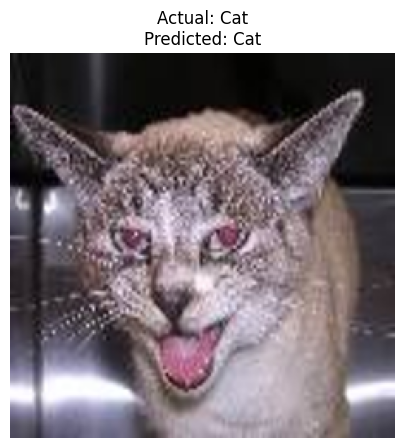

Prediction Probabilities:
Cat: 99.81%
Dog: 0.19%


In [35]:

sample_index = 0

sample_image = X_test_scaled[sample_index]
actual_label = y_test[sample_index]

sample_input = np.expand_dims(sample_image, axis=0)

prediction_logits = loaded_model.predict(sample_input, verbose=0)
prediction_probabilities = tf.nn.softmax(prediction_logits).numpy()[0]

predicted_label = np.argmax(prediction_probabilities)

class_names = ["Cat", "Dog"]

plt.figure(figsize=(5, 5))
plt.imshow(X_test[sample_index])
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)
plt.axis("off")
plt.show()

print("Prediction Probabilities:")
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {prediction_probabilities[i] * 100:.2f}%")



## 18. Project Conclusion

In this project, we developed a Cat vs Dog image classification model using Transfer Learning with MobileNetV2.

A balanced subset of 2,000 images was selected from the original dataset, containing 1,000 images from each class. The dataset was divided into training, validation, and testing sets using stratified sampling.

The pretrained MobileNetV2 model was used as a frozen feature extractor, while a Dense layer was trained for binary image classification.

### Final Model Performance

- Training Accuracy: 99.50%
- Validation Accuracy: 98.00%
- Test Accuracy: 98.67%
- Test Loss: 0.0356
- Correct Test Predictions: 296 out of 300

The model achieved strong classification performance on the test dataset. We also performed error analysis, visualized misclassified images, and successfully saved and reloaded the trained model.

### Limitations

- The model was trained using only 2,000 images instead of the complete 25,000-image dataset.
- The images were resized directly to 224 × 224, which may distort their original aspect ratios.
- The pretrained MobileNetV2 layers remained frozen throughout training.
- The evaluation was performed on a single random train-validation-test split.

### Future Improvements

- Train using a larger portion of the dataset.
- Experiment with data augmentation.
- Fine-tune selected layers of MobileNetV2.
- Compare performance with other pretrained CNN architectures.
- Evaluate the model on additional unseen datasets.
